# Read in output from Gaia

In this example, we read in a set of cluster observations from Gaia, and prep for feeding into StarStream

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
import agama

from StarStream import calc_prog_frame, GaiaStreamFromProgPDF, GaiaBackgroundPDF, optimize_mle

# isochrones is just for this notebook, not the package
from isochrones.mist import MIST_Isochrone 
mist = MIST_Isochrone()

## Load Gaia Data

Data returned from a Gaia Query like this one for NGC 6569: 
``` 
SELECT  gaia_source.designation,gaia_source.source_id,gaia_source.ra,gaia_source.dec,gaia_source.parallax,
gaia_source.parallax_error,gaia_source.pmra,gaia_source.pmra_error,gaia_source.pmdec,gaia_source.pmdec_error,
gaia_source.ruwe,gaia_source.phot_g_mean_flux,gaia_source.phot_g_mean_flux_error,gaia_source.phot_g_mean_mag,
gaia_source.phot_bp_mean_flux,gaia_source.phot_bp_mean_flux_error,gaia_source.phot_bp_mean_mag,
gaia_source.phot_rp_mean_flux,gaia_source.phot_rp_mean_flux_error,gaia_source.phot_rp_mean_mag,
gaia_source.bp_rp,gaia_source.radial_velocity,gaia_source.radial_velocity_error,gaia_source.phot_variable_flag,
gaia_source.non_single_star,gaia_source.has_xp_continuous,gaia_source.has_xp_sampled,gaia_source.has_rvs,
gaia_source.has_epoch_photometry,gaia_source.has_epoch_rv,gaia_source.has_mcmc_gspphot,gaia_source.has_mcmc_msc,
gaia_source.teff_gspphot,gaia_source.logg_gspphot,gaia_source.mh_gspphot,gaia_source.distance_gspphot,
gaia_source.azero_gspphot,gaia_source.ag_gspphot,gaia_source.ebpminrp_gspphot,'273.41125--31.82698' AS target_id,273.41125 AS target_ra,-31.82698 AS target_dec,
DISTANCE(
	POINT('ICRS', gaiadr3.gaia_source.ra, gaiadr3.gaia_source.dec), 
	POINT('ICRS', 273.41125, -31.82698) 
) AS "target_separation (deg)"

FROM gaiadr3.gaia_source 
WHERE 
CONTAINS(
	POINT('ICRS',gaiadr3.gaia_source.ra,gaiadr3.gaia_source.dec),
	CIRCLE('ICRS',273.41125,-31.82698,1)
)=1 ORDER BY target_id, "target_separation (deg)"
```

In [3]:
from astropy.table import Table
from astropy.io import ascii

# Load directly into an Astropy Table (recommended for most workflows)
tbl = Table.read("data/Pleaides_ala_Heyl.csv", format="csv")

# Inspect columns, units, and row count
print(tbl.colnames)
print(len(tbl))

#dataset = np.loadtxt("data/mock_dataset.txt")
#data_all = dataset[:,0:6]
#err_all = dataset[:,6:12]
#label_all = dataset[:,12].astype(bool)

['designation', 'source_id', 'ra', 'dec', 'parallax', 'parallax_error', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'ruwe', 'phot_g_mean_flux', 'phot_g_mean_flux_error', 'phot_g_mean_mag', 'phot_bp_mean_flux', 'phot_bp_mean_flux_error', 'phot_bp_mean_mag', 'phot_rp_mean_flux', 'phot_rp_mean_flux_error', 'phot_rp_mean_mag', 'bp_rp', 'radial_velocity', 'radial_velocity_error', 'phot_variable_flag', 'non_single_star', 'has_xp_continuous', 'has_xp_sampled', 'has_rvs', 'has_epoch_photometry', 'has_epoch_rv', 'has_mcmc_gspphot', 'has_mcmc_msc', 'teff_gspphot', 'logg_gspphot', 'mh_gspphot', 'distance_gspphot', 'azero_gspphot', 'ag_gspphot', 'ebpminrp_gspphot', 'target_id', 'target_ra', 'target_dec', 'target_separation (deg)']
347458


## Spatial and magnitude ranges to find streams

In [9]:
ra_range = (56.75-45.10*1.25, 56.75+45.1*1.25) # spatial range in deg
dec_range = (24.1167-45.10, 24.1167+45.10) # spatial range in deg
mag_cut = 22.0 # magnitude cut
mag_range = (0.0, mag_cut) # magnitude range

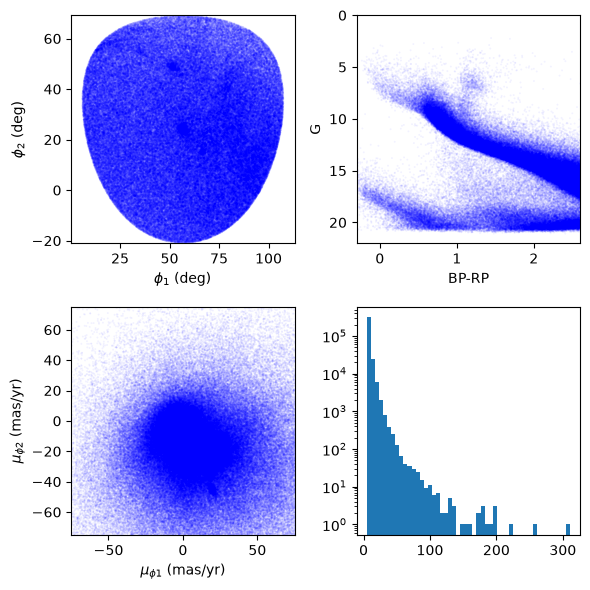

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(6,6))

axs[0,0].scatter(tbl['ra'], tbl['dec'], fc="b", ec="None", s=2, alpha=0.05)
axs[1,0].scatter(tbl['pmra'], tbl['pmdec'], fc="b", ec="None", s=2, alpha=0.05)
axs[0,1].scatter(tbl['phot_bp_mean_mag']-tbl['phot_rp_mean_mag'], tbl['phot_g_mean_mag'], fc="b", ec="None", s=2, alpha=0.05)
axs[1,1].hist(tbl['parallax'], bins=50, log=True)

axs[0,0].set_xlabel(r"$\phi_1$ (deg)")
axs[0,0].set_ylabel(r"$\phi_2$ (deg)")
axs[1,0].set_xlabel(r"$\mu_{\phi1}$ (mas/yr)")
axs[1,0].set_ylabel(r"$\mu_{\phi2}$ (mas/yr)")
axs[0,1].set_xlabel(r"BP-RP")
axs[0,1].set_ylabel(r"G")

axs[0,0].set_xlim(ra_range[0],ra_range[1])
axs[0,0].set_ylim(dec_range[0],dec_range[1])
axs[1,0].set_xlim(-75.0,75.0)
axs[1,0].set_ylim(-75.0,75.0)
axs[0,1].set_xlim(-0.3,2.6)
axs[0,1].set_ylim(mag_range[1],mag_range[0])

plt.tight_layout()
plt.show()

In [22]:
from astropy.coordinates import SkyCoord
cluster_coords = SkyCoord(
    ra=tbl["ra"] * u.deg, 
    dec=tbl["dec"] * u.deg, 
    distance=(tbl["parallax"] * u.mas).to(u.pc, u.parallax()),
    pm_ra_cosdec=tbl["pmra"] * (u.mas / u.yr), 
    pm_dec=tbl["pmdec"] * (u.mas / u.yr),
    radial_velocity = tbl["radial_velocity"] * u.km / u.s,
    frame="icrs")
Pleaides_galactocentric = cluster_coords.transform_to(coord.Galactocentric)

## Known parameters

We need to know some parameters of the toy Galaxy and GC ahead of time.

In [14]:
pot = agama.Potential("data/MWPotential2014.ini")

mass_gc = 670. # Msun - from Heyl et al. 2022 (as with XYZ and UVW coords below)
coord_gc = coord.Galactocentric(
    x=-120.99*u.pc,
    y=28.96*u.pc,
    z=-54.23*u.pc,
    v_x=-0.71*u.km/u.s,
    v_y=-28.3*u.km/u.s,
    v_z=-14.4*u.km/u.s
)
age_gyr = 0.1 # Gyr
log_age = np.log10(age_gyr * 1e9)  # 10.107 for 12.8 Gyr
feh = +0.03 #per google.

skycoord_gc = coord_gc.transform_to(coord.ICRS())
frame = calc_prog_frame(skycoord_gc)

iso = mist.isochrone(age=log_age, feh=feh) # if you never run this before, it'll take a while
iso_mini = iso["initial_mass"]
iso_color = iso["BP_mag"] - iso["RP_mag"]
iso_mag = iso["G_mag"]

## Next, let's find streams using the mixture model

### Construct PDFs for the stream and background

In [15]:
# construct PDFs using the same method in Chen+25

t_tot = 1.0 # Gyr
n_steps = 500
seed = 24 # use a different seed to make sure our success is not from luck

# stream PDF using particle spray from progenitor GC
pdf_stream = GaiaStreamFromProgPDF(
    pot, mass_gc, coord_gc, iso_mini, iso_color, iso_mag, 
    mag_cut=mag_cut, frame=frame, t_tot=t_tot, n_steps=n_steps, seed=seed
)

# background PDF from observed stars
pdf_bg = GaiaBackgroundPDF(Pleiades_galactocentric, field_range=field_range, mag_cut=mag_cut, seed=seed)

/Users/coveyk/Library/CloudStorage/Dropbox/python/StarStream-main/StarStream/agama_stream.py:33: FutureWarning: forceDeriv is deprecated, use Potential.eval(..., der=True) instead
  der = pot_host.forceDeriv(np.column_stack([x,y,z]))[1]
/Users/coveyk/Library/CloudStorage/Dropbox/python/StarStream-main/StarStream/agama_stream.py:138: FutureWarning: Consider using separateTime=True, which would enable optimized output storage: timestamps for all orbits put into a single 2d numpy array, and trajectories - into a single 3d array (see docstring for details). This will become the default option in a future version. Or add separateTime=False if you want to keep the deprecated format and suppress this warning.
  xv_stream = np.vstack(agama.orbit(potential=pot_tot,
998 orbits complete (1077 orbits/s)


NameError: name 'data_all' is not defined

### Estimate best-fit stream fraction using MLE

In [6]:
fbest, prob, frac_list, dlnL_list = optimize_mle(data_all, err_all, pdf_stream, pdf_bg)

print(f"The best-fit stream fraction from MLE is {fbest:.2e}")

The best-fit stream fraction from MLE is 1.58e-03


### Detection result

In [7]:
pth = 0.4 # threshold probability

mask_correct = (prob > pth) & label_all
print(f"Correct detection: {np.sum(mask_correct)}")

mask_missing = (prob <= pth) & label_all
print(f"Missing stars: {np.sum(mask_missing)}")

mask_false = (prob > pth) & ~label_all
print(f"False positives: {np.sum(mask_false)}")

Correct detection: 135
Missing stars: 34
False positives: 30


### Some visualizations of the detection

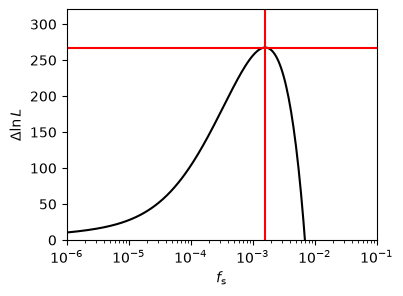

In [8]:
fig, ax0 = plt.subplots(1, 1, figsize=(4,3))

ax0.plot(frac_list, dlnL_list, c="k")

ax0.axvline(fbest, c="r")
ax0.axhline(np.max(dlnL_list), c="r")

ax0.set_xlabel(r"$f_{\rm s}$")
ax0.set_ylabel(r"$\Delta \ln L$")
ax0.set_xscale("log")
ax0.set_xlim(1e-6,1e-1)
ax0.set_ylim(0,np.max(dlnL_list)*1.2)

plt.show()

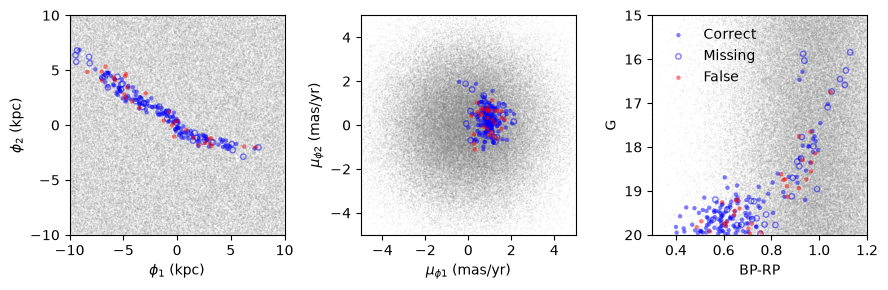

In [10]:
fig, [ax0, ax1, ax2] = plt.subplots(1, 3, figsize=(9,3))

ax0.scatter(data_all[:,0], data_all[:,1], fc="gray", ec="None", s=1, alpha=0.1)
ax1.scatter(data_all[:,2], data_all[:,3], fc="gray", ec="None", s=1, alpha=0.1)
ax2.scatter(data_all[:,4], data_all[:,5], fc="gray", ec="None", s=1, alpha=0.1)

ax0.scatter(data_all[mask_correct,0], data_all[mask_correct,1], fc="b", ec="None", s=10, alpha=0.5)
ax1.scatter(data_all[mask_correct,2], data_all[mask_correct,3], fc="b", ec="None", s=10, alpha=0.5)
ax2.scatter(data_all[mask_correct,4], data_all[mask_correct,5], fc="b", ec="None", s=10, alpha=0.5, label=r"Correct")

ax0.scatter(data_all[mask_missing,0], data_all[mask_missing,1], ec="b", fc="None", s=15, alpha=0.5)
ax1.scatter(data_all[mask_missing,2], data_all[mask_missing,3], ec="b", fc="None", s=15, alpha=0.5)
ax2.scatter(data_all[mask_missing,4], data_all[mask_missing,5], ec="b", fc="None", s=15, alpha=0.5, label=r"Missing")

ax0.scatter(data_all[mask_false,0], data_all[mask_false,1], fc="r", ec="None", s=10, alpha=0.5)
ax1.scatter(data_all[mask_false,2], data_all[mask_false,3], fc="r", ec="None", s=10, alpha=0.5)
ax2.scatter(data_all[mask_false,4], data_all[mask_false,5], fc="r", ec="None", s=10, alpha=0.5, label=r"False")

ax2.legend(loc="upper left", frameon=False)

ax0.set_xlabel(r"$\phi_1$ (kpc)")
ax0.set_ylabel(r"$\phi_2$ (kpc)")
ax1.set_xlabel(r"$\mu_{\phi1}$ (mas/yr)")
ax1.set_ylabel(r"$\mu_{\phi2}$ (mas/yr)")
ax2.set_xlabel(r"BP-RP")
ax2.set_ylabel(r"G")

ax0.set_xlim(*field_range)
ax0.set_ylim(*field_range)
ax1.set_xlim(-5.0,5.0)
ax1.set_ylim(-5.0,5.0)
ax2.set_xlim(0.3,1.2)
ax2.set_ylim(mag_range[1],mag_range[0])

plt.tight_layout()
plt.show()